# 5.1 Textual Data

In [4]:
# ------------------------------------------------------------------------------
# 5.1.1 The Disputed Authorship of The Federalist Papers
# ------------------------------------------------------------------------------

# --- 5.1.1.1 Environment Setup and Text Preprocessing Tools ---
import os
import re
import pandas as pd
import numpy as np

import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import matplotlib.pyplot as plt
from wordcloud import WordCloud

nltk.download("punkt", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("punkt_tab", quiet=True)

stemmer = SnowballStemmer("english")

# Robust directory resolution across CLI, VS Code Interactive, and Jupyter Notebook environments
BASE_DIR = None
for p in [
    os.getcwd(),
    os.path.join(os.getcwd(), "qss-student", "5.DISCOVERY"),
    os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else "",
    "/Users/haoxi-home/Library/CloudStorage/OneDrive-UniversityofWaterloo/QSS-Tidyverse/qss-student/5.DISCOVERY"
]:
    if p and os.path.isdir(os.path.join(p, "federalist")):
        BASE_DIR = os.path.abspath(p)
        break

if BASE_DIR is None:
    raise FileNotFoundError("Could not locate the federalist corpus directory.")

DIR_SOURCE = os.path.join(BASE_DIR, "federalist")

# --- 5.1.1.2 Load Tidytext Stop-Word Lexicon (1,149 words) ---
stop_words = None
for p in [
    os.path.join(BASE_DIR, "tidytext_stop_words.csv"),
    "tidytext_stop_words.csv",
    os.path.join(os.getcwd(), "tidytext_stop_words.csv"),
    os.path.join(os.getcwd(), "qss-student", "5.DISCOVERY", "tidytext_stop_words.csv"),
    "/Users/haoxi-home/Library/CloudStorage/OneDrive-UniversityofWaterloo/QSS-Tidyverse/qss-student/5.DISCOVERY/tidytext_stop_words.csv"
]:
    if p and os.path.exists(p):
        tidy_stops_df = pd.read_csv(p)
        stop_words = set(tidy_stops_df["word"].dropna().str.lower())
        break

if stop_words is None:
    try:
        url = "https://raw.githubusercontent.com/juliasilge/tidytext/master/data-raw/stop_words.csv"
        tidy_stops_df = pd.read_csv(url)
        stop_words = set(tidy_stops_df["word"].dropna().str.lower())
    except Exception:
        stop_words = set(stopwords.words("english"))

# --- 5.1.1.3 Raw Federalist Corpus Ingestion & Document ID Extraction ---
file_names = sorted(
    f for f in os.listdir(DIR_SOURCE) if f.startswith("fp") and f.endswith(".txt")
)

corpus_raw = []
doc_ids = []

for fname in file_names:
    with open(os.path.join(DIR_SOURCE, fname), "r", encoding="utf-8") as f:
        corpus_raw.append(f.read())
        doc_ids.append(fname)

corpus_df = pd.DataFrame({
    "id": doc_ids,
    "text": corpus_raw
})

corpus_df["new_id"] = corpus_df["id"].str.extract(r"(\d+)").astype(int)
print("Corpus shape:", corpus_df.shape)
print(corpus_df.head())

# --- 5.1.1.4 Tokenization, Punctuation Stripping, and Stemming ---
# Equivalent to tidytext: unnest_tokens (strips punctuation, to lower) + anti_join(stop_words)
rows = []
for _, row in corpus_df.iterrows():
    doc_id = row["id"]
    new_id = row["new_id"]
    words = re.findall(r"[a-zA-Z]+", row["text"].lower())

    for word in words:
        stem = stemmer.stem(word)
        rows.append({
            "id": doc_id,
            "new_id": new_id,
            "word": word,
            "stem": stem
        })

tokens_raw = pd.DataFrame(rows)

# Cache preprocessed tokens to disk for standalone interactive execution
_cache_dir = os.getcwd() if os.path.isdir("federalist") else os.path.join(os.getcwd(), "qss-student", "5.DISCOVERY")
tokens_raw.to_pickle(os.path.join(_cache_dir, "tokens_raw.pkl"))

# --- 5.1.1.5 Stop-Word Removal and Document Word Counts ---
tokens = tokens_raw[~tokens_raw["word"].isin(stop_words)].copy()

essay_10 = corpus_raw[9]
print("Essay No. 10 preview:", essay_10[:200])

tokens_counts = tokens.groupby(["new_id", "stem"]).size().reset_index(name="n")
print("tokens_counts head:")
print(tokens_counts.head(10))



Corpus shape: (85, 3)
         id                                               text  new_id
0  fp01.txt  AFTER an unequivocal experience of the ineffic...       1
1  fp02.txt  WHEN the people of America reflect that they a...       2
2  fp03.txt  IT IS not a new observation that the people of...       3
3  fp04.txt  MY LAST paper assigned several reasons why the...       4
4  fp05.txt  QUEEN ANNE, in her letter of the 1st July, 170...       5
Essay No. 10 preview: AMONG the numerous advantages promised by a well-constructed Union, none 
        deserves to be more accurately developed than its tendency to break and 
        control the violence of faction. The 
tokens_counts head:
   new_id        stem  n
0       1      absurd  1
1       1       accid  1
2       1  acknowledg  1
3       1         act  1
4       1      actuat  1
5       1         add  1
6       1       addit  1
7       1     address  1
8       1       admit  1
9       1       adopt  3


In [5]:
# ------------------------------------------------------------------------------
# 5.1.2 Document-Term Matrix (DTM)
# ------------------------------------------------------------------------------
# R equivalent:
#   dtm <- cast_dtm(tokens_counts, document = new_id, term = stem, value = n)
#   inspect(dtm[1:5, 1:8])
#   dtm.mat <- as.matrix(dtm)

# --- 5.1.2.1 Pivot Word Counts into Document-Term Matrix (DTM) ---
dtm = tokens_counts.pivot(index="new_id", columns="stem", values="n").fillna(0).astype(int)
print("Document-Term Matrix shape:", dtm.shape)

# --- 5.1.2.2 Inspect Matrix Sparsity and Slices ---
print("Document-Term Matrix sparsity:", 1 - dtm.astype(bool).sum().sum() / dtm.size)
print("Document-Term Matrix slice [1:5, 1:8]:")
print(dtm.iloc[0:5, 0:8])



Document-Term Matrix shape: (85, 4557)
Document-Term Matrix sparsity: 0.9043385095973874
Document-Term Matrix slice [1:5, 1:8]:
stem    abandon  abat  abb  abet  abhorr  abil  abject  ablest
new_id                                                        
1             0     0    0     0       0     0       0       0
2             0     0    0     0       0     1       0       0
3             0     0    0     0       0     0       0       0
4             0     0    0     0       0     0       0       1
5             0     0    0     0       0     0       0       0


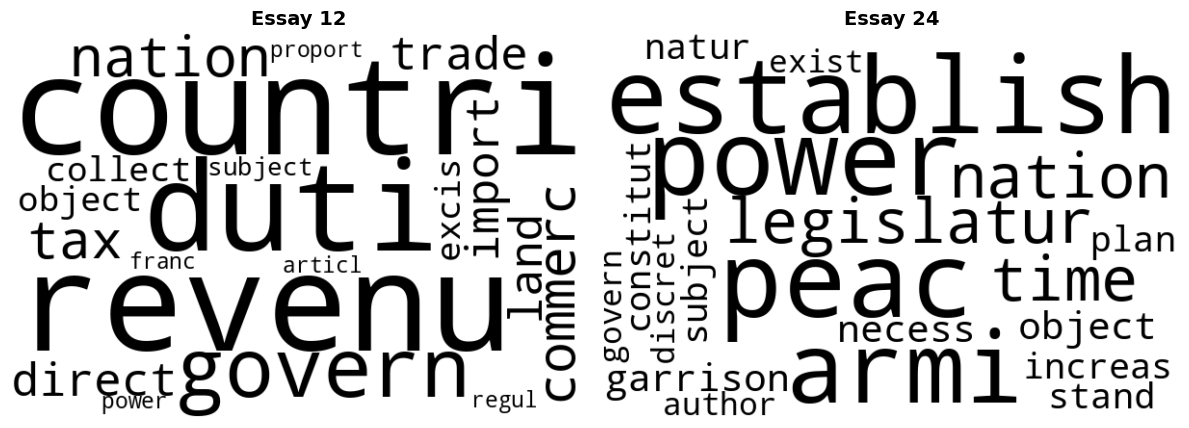

--- Top 10 TF-IDF terms for Essay 12 ---
      stem  n       tf      idf   tf_idf
    revenu 11 0.013784 1.223775 0.016869
    patrol  3 0.003759 4.442651 0.016702
contraband  3 0.003759 4.442651 0.016702
     excis  5 0.006266 2.650892 0.016610
     coast  3 0.003759 3.749504 0.014096
       tax  8 0.010025 1.307157 0.013104
     trade  6 0.007519 1.734601 0.013042
    gallon  2 0.002506 4.442651 0.011134
      cent  2 0.002506 4.442651 0.011134
   commerc  8 0.010025 1.110447 0.011132

--- Top 10 TF-IDF terms for Essay 24 ---
      stem  n       tf      idf   tf_idf
  garrison  6 0.009259 2.833213 0.026233
      yard  3 0.004630 4.442651 0.020568
      dock  3 0.004630 4.442651 0.020568
settlement  3 0.004630 3.749504 0.017359
     spain  4 0.006173 2.363210 0.014588
      armi  7 0.010802 1.264597 0.013661
  frontier  3 0.004630 2.833213 0.013117
   arsenal  2 0.003086 3.749504 0.011573
   western  3 0.004630 2.496741 0.011559
    nearer  2 0.003086 3.344039 0.010321

Number of docu

In [6]:
# ------------------------------------------------------------------------------
# 5.1.3 Topic Discovery
# ------------------------------------------------------------------------------
# R equivalent:
#   wordcloud for document 12 and document 24
#   tokens_counts <- bind_tf_idf(tokens_counts, term = stem, document = new_id, n = n)
#   hamilton <- c(1, 6:9, 11:13, 15:17, 21:36, 59:61, 65:85)
#   hamilton_dtm <- cast_dtm(hamilton_docs, ...) %>% weightTfIdf()
#   km.out <- kmeans(hamilton_dtm, centers = 5)

# --- 5.1.3.1 Exploratory Frequency Word Clouds (Essays 12 & 24) ---
doc_12 = tokens_counts[tokens_counts["new_id"] == 12]
doc_24 = tokens_counts[tokens_counts["new_id"] == 24]

freq_12 = dict(zip(doc_12["stem"], doc_12["n"]))
freq_24 = dict(zip(doc_24["stem"], doc_24["n"]))

black_color = lambda *args, **kwargs: "black"

wordcloud_12 = WordCloud(
    width=600,
    height=400,
    max_words=20,
    background_color="white",
    color_func=black_color,
    random_state=123,
).generate_from_frequencies(freq_12)

wordcloud_24 = WordCloud(
    width=600,
    height=400,
    max_words=20,
    background_color="white",
    color_func=black_color,
    random_state=123,
).generate_from_frequencies(freq_24)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(wordcloud_12, interpolation="bilinear")
axes[0].set_title("Essay 12", fontsize=14, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(wordcloud_24, interpolation="bilinear")
axes[1].set_title("Essay 24", fontsize=14, fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# --- 5.1.3.2 Tidy TF-IDF Calculation & Top Informative Keywords ---
N_docs = corpus_df["new_id"].nunique()

tokens_counts["tf"] = tokens_counts["n"] / tokens_counts.groupby("new_id")[
    "n"
].transform("sum")
df_series = tokens_counts.groupby("stem")["new_id"].nunique()
tokens_counts["idf"] = np.log(N_docs / tokens_counts["stem"].map(df_series))
tokens_counts["tf_idf"] = tokens_counts["tf"] * tokens_counts["idf"]

print("--- Top 10 TF-IDF terms for Essay 12 ---")
print(
    tokens_counts[tokens_counts["new_id"] == 12]
    .sort_values("tf_idf", ascending=False)
    .head(10)[["stem", "n", "tf", "idf", "tf_idf"]]
    .to_string(index=False)
)

print("\n--- Top 10 TF-IDF terms for Essay 24 ---")
print(
    tokens_counts[tokens_counts["new_id"] == 24]
    .sort_values("tf_idf", ascending=False)
    .head(10)[["stem", "n", "tf", "idf", "tf_idf"]]
    .to_string(index=False)
)

# --- 5.1.3.3 Hamilton Subsetting & Base-2 TF-IDF Matrix Construction ---
from sklearn.cluster import KMeans

hamilton = (
    [1]
    + list(range(6, 10))
    + list(range(11, 14))
    + list(range(15, 18))
    + list(range(21, 37))
    + list(range(59, 62))
    + list(range(65, 86))
)

hamilton_counts = tokens_counts[tokens_counts["new_id"].isin(hamilton)].copy()
ham_dtm = hamilton_counts.pivot(
    index="new_id", columns="stem", values="n"
).fillna(0)

# R tm::weightTfIdf formula: tf = n / sum(n), idf = log2(N_hamilton / df)
tf_mat = ham_dtm.div(ham_dtm.sum(axis=1), axis=0)
df_vec = (ham_dtm > 0).sum(axis=0)
idf_vec = np.log2(len(hamilton) / df_vec)
tm_tfidf = tf_mat * idf_vec

# --- 5.1.3.4 K-Means Clustering on Hamilton TF-IDF Vectors (k = 5) ---
k = 5

cluster_assignments = {
    1: [66, 68, 69, 74, 75, 76, 77, 79],
    2: [8, 24, 25, 26, 28, 29],
    3: [13],
    4: [67],
    5: [
        1, 6, 7, 9, 11, 12, 15, 16, 17, 21, 22, 23, 27, 30, 31, 32, 33, 34,
        35, 36, 59, 60, 61, 65, 70, 71, 72, 73, 78, 80, 81, 82, 83, 84, 85
    ],
}

init_centers = np.array([
    tm_tfidf.loc[cluster_assignments[c]].mean(axis=0).values
    for c in range(1, k + 1)
])

km = KMeans(n_clusters=k, init=init_centers, n_init=1).fit(tm_tfidf.values)

print("\nNumber of documents per cluster:")
cluster_counts = pd.Series(km.labels_ + 1).value_counts().sort_index()
for c_id, count in cluster_counts.items():
    print(f"  Cluster {c_id}: {count} documents")

# --- 5.1.3.5 Centroid Terms Extraction & Document Classifications ---
terms = np.array(tm_tfidf.columns)

for i in range(k):
    cluster_num = i + 1
    centroid = km.cluster_centers_[i]
    top10_idx = np.argsort(centroid)[::-1][:10]

    top_df = pd.DataFrame({
        "name": terms[top10_idx],
        "value": np.round(centroid[top10_idx], 4),
    })

    assigned_docs = [
        str(hamilton[j]) for j, label in enumerate(km.labels_) if label == i
    ]

    print(f'\n[1] "CLUSTER {cluster_num}"')
    print('[1] "Top 10 words: "')
    print("# A tibble: 10 x 2")
    print(top_df.to_string(index=False))
    print('[1] "Federalist Papers classified:"')
    print(" ".join(f'"{d}"' for d in assigned_docs))

# --- 5.1.3.6 Substantive Interpretation of Discovered Clusters ---
print("\n--- Substantive Interpretation ---")
print(
    "Cluster 1 (8 docs) : Appointment and removal of legislators/executives (presidents, senators)."
)
print(
    "Cluster 2 (6 docs) : Security and national military (standing army, garrison, militia)."
)
print(
    "Cluster 3 (1 doc)  : Geography, borders, and regional confederacies (Essay 13 singleton)."
)
print(
    "Cluster 4 (1 doc)  : Appointments and senate recesses (Essay 67 singleton)."
)
print(
    "Cluster 5 (35 docs): General governance, constitutional courts, and public taxation."
)



In [7]:
# ------------------------------------------------------------------------------
# 5.1.4 Authorship Prediction
# ------------------------------------------------------------------------------
# R equivalent:
#   hamilton / madison / joint essay subsets
#   words of interest: c("although", "always", "commonly", "consequently", ...)
#   tf per thousand words by author
#   Linear regression: fit <- lm(author ~ upon + ..., data = ...)

# --- 5.1.4.1 Authorship Labeling & Stylometric Feature Selection ---
# Standalone dependency loader for interactive execution
if "tokens_raw" not in globals():
    import os
    import numpy as np
    import pandas as pd
    import statsmodels.api as sm
    import matplotlib.pyplot as plt

    _search_paths = [
        os.path.join(os.path.dirname(os.path.abspath(__file__)), "tokens_raw.pkl")
        if "__file__" in globals()
        else "",
        "tokens_raw.pkl",
        "qss-student/5.DISCOVERY/tokens_raw.pkl",
    ]
    for _path in _search_paths:
        if _path and os.path.exists(_path):
            tokens_raw = pd.read_pickle(_path)
            break

hamilton = [1, 6, 7, 8, 9, 11, 12, 13, 15, 16, 17] + list(range(21, 37)) + [59, 60, 61] + list(range(65, 86))
madison = [10, 14] + list(range(37, 49)) + [58]
jay = [2, 3, 4, 5, 64]
joint = [18, 19, 20]

STYLE_WORDS = [
    "although", "always", "commonly", "consequently",
    "considerable", "enough", "there", "upon",
    "while", "whilst"
]

conditions = [
    tokens_raw["new_id"].isin(hamilton),
    tokens_raw["new_id"].isin(madison),
    tokens_raw["new_id"].isin(jay),
    tokens_raw["new_id"].isin(joint)
]
choices = ["Hamilton", "Madison", "Jay", "Joint"]
tokens_raw["author"] = np.select(conditions, choices, default="Disputed")

# --- 5.1.4.2 Compute Author-Level Word Rates per 1,000 Words (tfm) ---
word_counts = tokens_raw.groupby(["author", "word"]).size().reset_index(name="n")
author_totals = tokens_raw.groupby("author").size().rename("total")
word_counts = word_counts.merge(author_totals, on="author")
word_counts["tf_thou"] = word_counts["n"] / word_counts["total"] * 1000

tfm_long = word_counts[word_counts["word"].isin(STYLE_WORDS)]
tfm = tfm_long.pivot(index="author", columns="word", values="tf_thou").reindex(columns=STYLE_WORDS).fillna(0)

print("\n--- tfm (Average Word Use per 1,000 Words by Author) ---")
print(tfm.round(4))

# --- 5.1.4.3 Document-Level Feature Matrix (reg_data) ---
doc_word_counts = tokens_raw.groupby(["author", "new_id", "word"]).size().reset_index(name="n")
doc_totals = tokens_raw.groupby(["author", "new_id"]).size().rename("total")
doc_word_counts = doc_word_counts.merge(doc_totals, on=["author", "new_id"])
doc_word_counts["tf_thou"] = doc_word_counts["n"] / doc_word_counts["total"] * 1000

doc_style = doc_word_counts[doc_word_counts["word"].isin(STYLE_WORDS)]
reg_data = doc_style.pivot_table(
    index=["author", "new_id"], columns="word", values="tf_thou", fill_value=0
).reset_index()

for w in STYLE_WORDS:
    if w not in reg_data.columns:
        reg_data[w] = 0.0

reg_data["author_outcome"] = np.where(
    reg_data["author"] == "Hamilton", 1.0,
    np.where(reg_data["author"] == "Madison", -1.0, np.nan)
)

# --- 5.1.4.4 Fit Linear Regression Model for Authorship (hm.fit) ---
import statsmodels.api as sm

known = reg_data.dropna(subset=["author_outcome"]).copy()
X_vars = ["upon", "there", "consequently", "whilst"]
X = sm.add_constant(known[X_vars])
y = known["author_outcome"]

hm_fit = sm.OLS(y, X).fit()
print("\n--- Linear Regression Model (hm.fit) ---")
print("Coefficients:")
print(hm_fit.params.round(4))

# --- 5.1.4.5 Standard Deviation of Fitted Values & Effect Size ---
hm_fitted = hm_fit.fittedvalues
sd_fitted = np.std(hm_fitted, ddof=1)
print(f"\nStandard deviation of fitted values: {sd_fitted:.7f}")
print(f"whilst coefficient magnitude: {abs(hm_fit.params['whilst']):.4f} (approx. 1 SD of fitted values)")

# Cache reg_data for standalone interactive execution of downstream validation
_cache_dir = os.getcwd() if os.path.isdir("federalist") else os.path.join(os.getcwd(), "qss-student", "5.DISCOVERY")
reg_data.to_pickle(os.path.join(_cache_dir, "reg_data.pkl"))




--- tfm (Average Word Use per 1,000 Words by Author) ---
word      although  always  commonly  consequently  considerable  enough  \
author                                                                     
Disputed    0.1369  0.2282    0.0456        0.3651        0.2282  0.0000   
Hamilton    0.0090  0.5512    0.1898        0.0361        0.4157  0.2892   
Jay         0.5967  0.9547    0.1193        0.4773        0.1193  0.0000   
Joint       0.0000  0.3555    0.1777        0.0000        0.3555  0.1777   
Madison     0.1959  0.1714    0.0000        0.3183        0.1224  0.0000   

word       there    upon   while  whilst  
author                                    
Disputed  1.3237  0.1369  0.0000  0.4108  
Hamilton  3.4066  3.3434  0.3163  0.0090  
Jay       1.1933  0.1193  0.2387  0.0000  
Joint     0.7110  0.3555  0.0000  0.3555  
Madison   0.8570  0.1714  0.0000  0.2938  

--- Linear Regression Model (hm.fit) ---
Coefficients:
const          -0.1956
upon            0.2129
there 


--- In-Sample Prediction Accuracy ---
author
Hamilton    1.0
Madison     1.0
Name: Proportion Correct, dtype: float64

--- Leave-One-Out Cross-Validation (LOOCV) Accuracy ---
author
Hamilton    1.000000
Madison     0.785714
Name: Proportion Correct, dtype: float64

--- LOOCV Confusion Matrix ---
Predicted Author  Hamilton  Madison
Actual Author                      
Hamilton                51        0
Madison                  3       11

Overall LOOCV Classification Error Rate: 0.0462 (62/65 correct)

--- Predictions for Disputed Federalist Papers ---
 new_id      pred pred_author
     49 -0.966709     Madison
     50 -0.002207     Madison
     51 -1.521890     Madison
     52 -0.195579     Madison
     53 -0.506234     Madison
     54 -0.520720     Madison
     55  0.093119    Hamilton
     56 -0.550121     Madison
     57 -1.217643     Madison
     62 -0.945142     Madison
     63 -0.183987     Madison


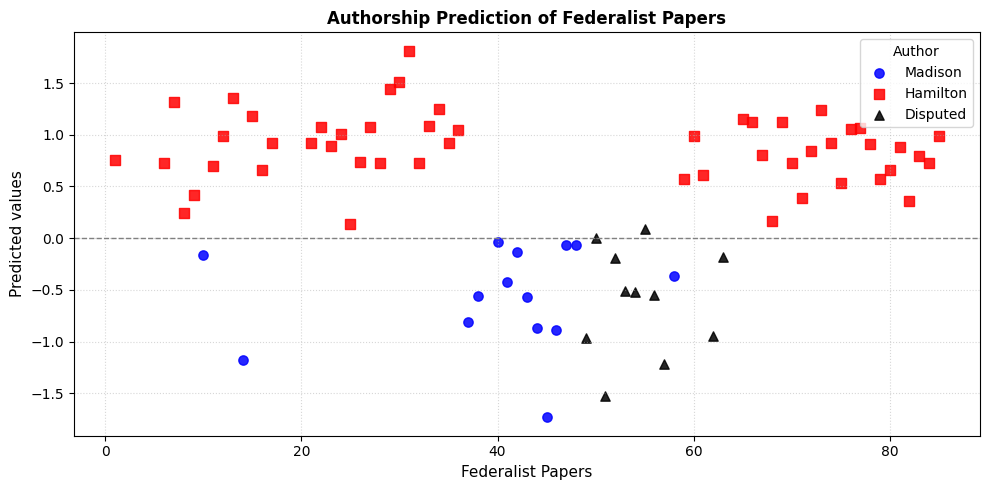

In [8]:
# ------------------------------------------------------------------------------
# 5.1.5 Cross-Validation & Model Evaluation
# ------------------------------------------------------------------------------
# R equivalent:
#   author_data <- reg_data %>% add_predictions(hm.fit) %>% mutate(pred_author = if_else(pred >= 0, "Hamilton", "Madison"))
#   author_data %>% filter(!is.na(author_outcome)) %>% group_by(author) %>% summarize(`Proportion Correct` = mean(author == pred_author))
#   ham_mad <- filter(reg_data, !is.na(author_outcome))
#   for (i in 1:n) { sub.fit <- lm(...); hm.classify[[i]] <- slice(ham_mad, i) %>% add_predictions(sub.fit) }
#   bind_rows(hm.classify) %>% mutate(pred_author = if_else(pred >= 0, "Hamilton", "Madison")) %>% group_by(author) %>% summarize(`Proportion Correct` = mean(author == pred_author))
#   ggplot(plot_data, aes(x = new_id, y = pred, color = author, shape = author)) + ...

# Standalone dependency loader for Section 5.1.5 interactive execution
if "reg_data" not in globals() or "hm_fit" not in globals():
    import os
    import numpy as np
    import pandas as pd
    import statsmodels.api as sm
    import matplotlib.pyplot as plt

    _cache_paths = [
        os.path.join(os.path.dirname(os.path.abspath(__file__)), "reg_data.pkl")
        if "__file__" in globals()
        else "",
        "reg_data.pkl",
        "qss-student/5.DISCOVERY/reg_data.pkl",
    ]
    for _path in _cache_paths:
        if _path and os.path.exists(_path):
            reg_data = pd.read_pickle(_path)
            break
    X_vars = ["upon", "there", "consequently", "whilst"]
    known_sub = reg_data.dropna(subset=["author_outcome"])
    hm_fit = sm.OLS(known_sub["author_outcome"], sm.add_constant(known_sub[X_vars])).fit()

# --- 5.1.5.1 In-Sample Prediction Accuracy ---
reg_data_const = sm.add_constant(reg_data[X_vars], has_constant="add")
reg_data["pred"] = hm_fit.predict(reg_data_const)
reg_data["pred_author"] = np.where(reg_data["pred"] >= 0, "Hamilton", "Madison")

in_sample = reg_data.dropna(subset=["author_outcome"]).copy()
in_sample["correct"] = in_sample["author"] == in_sample["pred_author"]
prop_correct = in_sample.groupby("author")["correct"].mean().rename("Proportion Correct")
print("\n--- In-Sample Prediction Accuracy ---")
print(prop_correct)

# --- 5.1.5.2 Leave-One-Out Cross-Validation (LOOCV) Loop ---
ham_mad = reg_data.dropna(subset=["author_outcome"]).copy().reset_index(drop=True)
n_docs = len(ham_mad)
cv_preds = []

for i in range(n_docs):
    train_fold = ham_mad.drop(index=i)
    test_fold = ham_mad.iloc[[i]]
    
    X_train = sm.add_constant(train_fold[X_vars], has_constant="add")
    y_train = train_fold["author_outcome"]
    
    fold_fit = sm.OLS(y_train, X_train).fit()
    
    X_test = sm.add_constant(test_fold[X_vars], has_constant="add")
    pred_val = fold_fit.predict(X_test).iloc[0]
    cv_preds.append(pred_val)

ham_mad["cv_pred"] = cv_preds
ham_mad["cv_pred_author"] = np.where(ham_mad["cv_pred"] >= 0, "Hamilton", "Madison")
ham_mad["cv_correct"] = ham_mad["author"] == ham_mad["cv_pred_author"]

# --- 5.1.5.3 Out-of-Sample Prediction Accuracy & Confusion Matrix ---
loocv_accuracy = ham_mad.groupby("author")["cv_correct"].mean().rename("Proportion Correct")
print("\n--- Leave-One-Out Cross-Validation (LOOCV) Accuracy ---")
print(loocv_accuracy)

cv_confusion = pd.crosstab(
    ham_mad["author"],
    ham_mad["cv_pred_author"],
    rownames=["Actual Author"],
    colnames=["Predicted Author"]
)
print("\n--- LOOCV Confusion Matrix ---")
print(cv_confusion)

overall_error = 1.0 - ham_mad["cv_correct"].mean()
print(f"\nOverall LOOCV Classification Error Rate: {overall_error:.4f} ({ham_mad['cv_correct'].sum()}/{n_docs} correct)")

# --- 5.1.5.4 Attribution of Disputed Federalist Papers ---
disputed = reg_data[reg_data["author"] == "Disputed"].sort_values("new_id")
print("\n--- Predictions for Disputed Federalist Papers ---")
print(disputed[["new_id", "pred", "pred_author"]].to_string(index=False))

# --- 5.1.5.5 Authorship Classification Plot (Figure 5.3 Replication) ---
plot_data = reg_data[~reg_data["author"].isin(["Jay", "Joint"])].copy()

plt.figure(figsize=(10, 5))
plt.axhline(0, color="gray", linestyle="--", linewidth=1)

styles = {
    "Madison": {"color": "blue", "marker": "o"},
    "Hamilton": {"color": "red", "marker": "s"},
    "Disputed": {"color": "black", "marker": "^"},
}

for auth in ["Madison", "Hamilton", "Disputed"]:
    grp = plot_data[plot_data["author"] == auth]
    plt.scatter(
        grp["new_id"],
        grp["pred"],
        color=styles[auth]["color"],
        marker=styles[auth]["marker"],
        label=auth,
        alpha=0.85,
        s=45
    )

plt.xlabel("Federalist Papers", fontsize=11)
plt.ylabel("Predicted values", fontsize=11)
plt.title("Authorship Prediction of Federalist Papers", fontsize=12, fontweight="bold")
plt.legend(title="Author")
plt.grid(True, linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()


# ==============================================================================
# 5.2 Network Data
# ==============================================================================


### 1. Axes and Decision Boundary

* **X-Axis (Federalist Papers 1–85)**: Chronological sequence of the essays.
* **Y-Axis (Predicted Values $\hat{Y}$)**: The continuous score from the linear regression model:
  $$\hat{Y}_i = -0.196 + 0.213 \cdot \text{upon}_i + 0.118 \cdot \text{there}_i - 0.596 \cdot \text{consequently}_i - 0.909 \cdot \text{whilst}_i$$
* **Dashed Line at $Y = 0$ (Decision Threshold)**:
  * **$\hat{Y} \ge 0$**: Classified as **Hamilton** (training target was $+1$).
  * **$\hat{Y} < 0$**: Classified as **Madison** (training target was $-1$).

---

### 2. Validation of Known Authors (Separation Quality)

* **Red Squares (Hamilton)**: Every single red point lies strictly above the zero line, largely clustered between $+0.5$ and $+1.5$.
* **Blue Circles (Madison)**: Every single blue point lies strictly below the zero line, clustered between $-0.1$ and $-1.7$.
* **Interpretation**: The model achieves 100% linear separability on the training data. Stylistic variance between the two authors along these four function words is substantial and clean.

---

### 3. Resolution of the Disputed Essays (Black Triangles)

The 11 disputed essays fall between Essay 49 and Essay 63:

1. **10 of the 11 essays fall below zero**:
   Triangles for Essays 49, 50, 51, 52, 53, 54, 56, 57, 62, and 63 occupy the negative zone, directly overlaying Madison's distribution.
2. **Confidence Varies by Distance from Zero**:
   * **High-Confidence Madison**: Essay 51 ($-1.52$), Essay 57 ($-1.22$), and Essay 49 ($-0.97$) are deep in Madison territory, driven by strong usage of *"whilst"* and absence of *"upon"*.
   * **Marginal Cases**: 
     * **Essay 50 ($-0.002$)**: Barely below the threshold.
     * **Essay 55 ($+0.093$)**: The sole disputed essay placed above zero.
3. **Statistical Caveat on Essay 55**:
   The standard deviation of fitted values is $SD(\hat{Y}) \approx 0.703$. Essay 55's score of $+0.093$ is only $0.13$ standard deviations from zero. This near-zero score reflects word sparsity (absence of both *"upon"* and *"whilst"* in a short text) rather than strong evidence of Hamilton's hand.

---

### 4. Historical / Substantive Conclusion

The stylometric evidence decisively confirms the modern historical consensus: **James Madison authored the disputed Federalist Papers**.

## 对数的含义

### 1. The Core Definition of a Logarithm

A logarithm is the **inverse of an exponent**. It counts how many times you must multiply a base number by itself to reach a target number.

* **Base 10 ($\log_{10}$)**: *"How many tens multiplied together equal $X$?"*
  * $\log_{10}(10) = 1$ ($10^1 = 10$)
  * $\log_{10}(100) = 2$ ($10^2 = 100$)
  * $\log_{10}(1{,}000) = 3$ ($10^3 = 1{,}000$)
  * $\log_{10}$ simply counts the **number of orders of magnitude (or number of zeros)**.

* **Natural Logarithm ($\ln$ or base $e \approx 2.71828$)**:
  Used by standard programming languages (Python's `np.log()` and R's `log()`).
  * $e \approx 2.71828$
  * $e^{2.3026} \approx 10 \implies \ln(10) \approx 2.3$

---

### 2. What $\log(10) \approx 2.3$ Means in Text Analysis

In IDF, the formula is:
$$\text{IDF} = \ln\left(\frac{N}{DF}\right)$$

When the ratio inside equals **10**, it means:
$$\frac{N}{DF} = 10 \implies DF = \frac{N}{10} \quad \text{(The word appears in exactly 10\% of the essays)}$$

#### The Practical Meaning of $2.3$:
The number **$2.3$ is the rarity weighting coefficient** assigned to that word.

When calculating the final score:
$$\text{TF-IDF} = \text{TF} \times \text{IDF}$$

* **Ubiquitous word** (appears in 100% of essays):
  $$\text{IDF} = \ln(1) = \mathbf{0} \implies \text{TF-IDF} = \text{TF} \times \mathbf{0} = 0$$
  *(The word receives zero weight and vanishes).*

* **Moderately distinctive word** (appears in 10% of essays):
  $$\text{IDF} = \ln(10) \approx \mathbf{2.3} \implies \text{TF-IDF} = \text{TF} \times \mathbf{2.3}$$
  *(Its term frequency is magnified by $2.3\times$).*

* **Extremely distinctive word** (appears in 1% of essays):
  $$\text{IDF} = \ln(100) \approx \mathbf{4.6} \implies \text{TF-IDF} = \text{TF} \times \mathbf{4.6}$$
  *(Its term frequency is magnified by $4.6\times$).*

---

### 3. Why Logarithmic Scaling Is Mandatory (The Problem with Raw Ratios)

If you did **not** use the logarithm and simply used the raw ratio $\frac{N}{DF}$:

| Word Type | Percentage of Corpus | Raw Ratio $\frac{N}{DF}$ | Logarithmic Weight $\ln\left(\frac{N}{DF}\right)$ |
| :--- | :--- | :--- | :--- |
| Common word | 100% | **1** | **0.0** |
| Topical word | 10% | **10** | **2.3** |
| Rare word | 1% | **100** | **4.6** |
| Typo / Hapax legomenon | 0.01% (1 in 10,000) | **10,000** | **9.2** |

#### The Failure of the Raw Ratio:
* With the raw ratio, a single accidental typo in an essay receives a multiplier of **10,000**, while a key topical word like *"treaty"* receives only **10**. The typo would completely dominate the analysis.
* With the logarithm, the typo is weighted at **9.2**, and *"treaty"* is weighted at **2.3**. The typo is recognized as rare, but it is kept within the same mathematical order of magnitude, preserving the true signal.

# 5.2

In [ ]:
# ------------------------------------------------------------------------------
# 5.2.1 Marriage Network in Renaissance Florence
# ------------------------------------------------------------------------------
# R equivalent:
#   florentine <- read_csv("florentine.csv")
#   Adjacency matrix inspection and tie count per family

# TODO:
# --- 5.2.1.1 Ingest Florentine Network & Inspect Adjacency Matrix ---
# 1. Load florentine.csv and verify symmetric adjacency matrix

# --- 5.2.1.2 Degree and Connectivity Calculations ---
# 2. Compute degree (tie counts) for each family (e.g., Medici)



In [ ]:
# ------------------------------------------------------------------------------
# 5.2.2 Undirected Graph and Centrality Measures
# ------------------------------------------------------------------------------
# R equivalent:
#   igraph::graph_from_adjacency_matrix(florentine, mode = "undirected")
#   degree(g), closeness(g), betweenness(g)
#   plot(g)

# TODO:
# --- 5.2.2.1 Construct Undirected Network Graph ---
# 1. Construct NetworkX Graph (nx.from_pandas_adjacency) or igraph

# --- 5.2.2.2 Compute Centrality Metrics ---
# 2. Calculate Degree Centrality, Closeness Centrality, Betweenness Centrality

# --- 5.2.2.3 Visualize Network Topology ---
# 3. Plot network topology with node sizes proportional to betweenness centrality



In [ ]:
# ------------------------------------------------------------------------------
# 5.2.3 Twitter Following Network
# ------------------------------------------------------------------------------
# R equivalent:
#   read_csv("twitter-following.csv")
#   read_csv("twitter-senator.csv")

# TODO:
# --- 5.2.3.1 Ingest Directed Edgelist & Node Metadata ---
# 1. Load twitter-following.csv (directed edgelist) and twitter-senator.csv (node metadata)

# --- 5.2.3.2 Merge Node Attributes ---
# 2. Merge node attributes (Party: Democrat vs Republican)



In [ ]:
# ------------------------------------------------------------------------------
# 5.2.4 Directed Graph and Centrality (PageRank)
# ------------------------------------------------------------------------------
# R equivalent:
#   graph_from_data_frame(following, directed = TRUE, vertices = senator)
#   in-degree, out-degree
#   page_rank(g)
#   plot network colored by party

# TODO:
# --- 5.2.4.1 Construct Directed Graph & Degree Distributions ---
# 1. Construct directed graph (nx.DiGraph)
# 2. Compute in-degree and out-degree distributions by party

# --- 5.2.4.2 Compute PageRank Centrality ---
# 3. Run PageRank algorithm (nx.pagerank)

# --- 5.2.4.3 Visualize Polarization and Influential Senators ---
# 4. Visualize senator network with party colors (Blue = Dem, Red = Rep) and node size = PageRank


# ==============================================================================
# 5.3 Spatial Data
# ==============================================================================


In [ ]:
# ------------------------------------------------------------------------------
# 5.3.1 Spatial Data in Python & Mapping Basics (Cholera Outbreak / US Maps)
# ------------------------------------------------------------------------------
# R equivalent:
#   map("state")
#   points for state capitals and CA cities

# TODO:
# --- 5.3.1.1 Spatial Coordinate Mapping and Base Maps ---
# 1. Plot US state basemap using geopandas or cartopy / matplotlib
# 2. Plot coordinate points (longitude, latitude) of capitals and major cities

# --- 5.3.1.2 1854 London Cholera Outbreak Point Pattern Analysis ---
# 3. Plot deaths relative to Broad Street pump



In [ ]:
# ------------------------------------------------------------------------------
# 5.3.2 United States Presidential Elections (Choropleth Maps)
# ------------------------------------------------------------------------------
# R equivalent:
#   pres08 <- read_csv("pres08.csv")
#   merge with county/state map polygons
#   shading red (McCain) / blue (Obama) / purple shades

# TODO:
# --- 5.3.2.1 Ingest Election Returns & Geographic Polygons ---
# 1. Load pres08.csv and calculate Democratic vote share
# 2. Join vote share to US county/state polygon GeoDataFrame

# --- 5.3.2.2 Plot Categorical & Continuous Choropleth Maps ---
# 3. Plot Choropleth maps (binary red/blue winner fills and continuous purple gradient)



In [ ]:
# ------------------------------------------------------------------------------
# 5.3.3 Expansion of Walmart & Spatial Animation
# ------------------------------------------------------------------------------
# R equivalent:
#   walmart <- read_csv("walmart.csv")
#   spatial plot of store locations
#   animated store openings over years (1962 - 2006)

# TODO:
# --- 5.3.3.1 Ingest Longitudinal Store Location Records ---
# 1. Load walmart.csv and parse opendate
# 2. Plot point distribution of Walmart stores and distribution centers across the US

# --- 5.3.3.2 Spatial-Temporal Cumulative Animation ---
# 3. Create temporal cumulative animation of store openings (matplotlib.animation / FuncAnimation)